# 07-机械臂运动学逆解


## 1. 本篇范围与任务

上一笔记解决了运动学正解：知道各关节的位置，就能根据机械臂模型计算末端位姿。

实际任务通常从相反方向提出。例如，课件要求机械臂移动到桌面坐标 `(x, y, z)`，保持手爪垂直向下，抓取杯子。此时已知的是期望末端位姿，需要求出各关节应到达的位置。

这就是**运动学逆解（Inverse Kinematics，IK）**，也称逆运动学。

本篇依据 `具身智能实战04-运动学逆解.pptx` 全部 **23 页**整理。课件标题为“从‘正向推理’到‘逆向溯源’：运动学逆解（IK）入门”，主要内容是逆解的挑战、解析与数值两种求解思想，以及不同工程场景的选择。

第 21 页有二连杆演示截图，但没有展示程序源码或启动步骤。笔记保留原图，并将解释二连杆公式所需的短推导标为补充。


## 2. 正解与逆解的方向

课件第 2 页回顾正解：在模型与参考坐标系确定后，一组关节变量 `q` 对应一个末端位姿 `X`。

$$
\mathbf X=f(\mathbf q)
$$

其中，关节变量可以写为 `q = [q₁, q₂, ..., qₙ]`，任务空间位姿包含位置与朝向。

逆解将输入改成期望位姿 `X_desired`，求满足目标的关节变量。课件第 4 页用下面的写法表达这个方向：

$$
\mathbf q=f^{-1}(\mathbf X_{\mathrm{desired}})
$$

第 4 页的对照表可整理为：

| 对比项 | 正向运动学（FK） | 逆向运动学（IK） |
|---|---|---|
| 方向 | 从关节空间到任务空间 | 从任务空间到关节空间 |
| 输入 | 已知的关节变量 | 期望的末端位姿 |
| 求解问题 | 这些关节位置对应的末端在哪里？ | 怎样设置关节，才能让末端到达目标？ |
| 解的性质 | 给定构型对应确定的末端位姿 | 可能无解、单解或多解 |

> **补充说明：**这里的 `f⁻¹` 是逆向求解的示意，不能直接理解为始终存在的单值反函数。更准确的任务是寻找满足 `f(q) = X_desired` 的关节变量；这样的变量可能不存在，也可能有多个。

还要区分“给定关节构型得到唯一位姿”与“一个位姿只对应一组关节构型”。前者是当前模型的正解性质，后者通常不成立。


## 3. 逆解为什么更难

课件第 5 页先列出四个方面，再集中讨论多解、无解和奇异性。

| 挑战 | 含义 |
|---|---|
| 非线性（Non-linearity） | 关节变量通过三角函数等非线性关系影响末端，难以直接反解 |
| 解的存在性（Existence） | 目标可能不在机械臂能够实现的范围内 |
| 解的多样性（Multiplicity） | 同一个目标可能对应不同关节构型 |
| 奇异性（Singularity） | 某些构型使局部运动映射退化，求解与控制更困难 |

因此，逆解不只是“把正解公式移项”。求解前要明确目标包含哪些位置与姿态约束，求解后还要判断结果是否符合机械臂自身的限制。


## 4. 多解性：同一个目标对应不同构型

课件第 6 页用手臂触摸头顶上方某个点作类比：可以抬高肘部，也可以降低肘部，指尖仍然接触同一点。

第 7 页将这种现象转成二连杆平面模型：

- 基座固定在 `O`。
- 第一连杆长度为 `L₁`。
- 第二连杆长度为 `L₂`。
- 末端需要到达目标点 `P`。

### 4.1 用两个圆确定肘部位置

1. 以基座 `O` 为圆心、`L₁` 为半径画圆 `C₁`，表示肘关节可能的位置。
2. 以目标 `P` 为圆心、`L₂` 为半径画圆 `C₂`，表示与目标相距第二连杆长度的位置。
3. 找两个圆的交点。每个交点同时满足两段连杆的长度要求，可以作为肘关节的位置。

通常，两个圆相交于两点，对应课件所说的“高手肘”和“低手肘”两种构型。同一个末端位置由此产生两组关节解。

> **补充说明：**这个几何例子只约束末端位置，两种解的末端朝向通常不同。如果任务还要求手爪具有特定朝向，需要另外判断是否满足。逆解得到的构型也不同于从当前构型运动到它的完整路径。

“高手肘”“低手肘”的命名依赖坐标系和观察方向；数学上可以先按两个角度分支区分，避免混淆。


## 5. 冗余自由度与解的选择

课件第 8 页讨论更高维模型：当机器人具有相对于当前任务多出来的自由度，也就是**冗余自由度**时，满足同一目标的构型可能形成连续的解空间。

课件列举了利用这些自由度的方向：

- 改变中间部件的位置，以帮助避开障碍物。
- 按能耗或运动平顺性选择构型。
- 尽量远离奇异位形。

多解性因此既带来选择问题，也给优化留下空间。目标点相同，不同解可能具有不同的关节位置、余量和运动代价。

> **补充说明：**是否冗余需要结合任务约束判断，不能只看机器人有几个关节。位置任务与位置加朝向任务所需的自由度不同。能够选择多个解，也不表示求解器已经自动完成避障或能耗优化，还需要相应模型与约束。


## 6. 无解性与工作空间

课件第 9 页将**工作空间（Workspace）**定义为机器人末端能够到达的点的集合。目标在工作空间之外，就无法通过关节调整到达。

第 10 页用前面的两个圆解释两种无解情况。

### 6.1 目标太远

目标到基座的距离大于两段连杆长度之和，手臂即使完全伸直也无法达到。两个圆相距太远，没有交点。

### 6.2 基座附近的空洞

如果两段长度不同，较短的连杆即使完全折回，也不能抵消较长的连杆。基座附近可能形成无法触及的区域。

此时一个圆被另一个圆包含，且边界没有交点，因此同样无解。

### 6.3 二连杆的距离条件

> **补充公式：**对于长度为正、关节可自由旋转、只要求末端位置的理想二连杆平面臂，设目标到基座的距离为 `r = √(x²+y²)`，可达条件是：

$$
|L_1-L_2|\le r\le L_1+L_2
$$

| 目标距离 | 两个圆的关系 | 理想模型中的结果 |
|---|---|---|
| `r > L₁+L₂` | 相距太远 | 无解 |
| `r < abs(L₁−L₂)` | 一个圆在另一个内部且不相交 | 无解 |
| 严格位于上下限之间 | 相交于两点 | 通常有两种肘部构型 |
| 位于非退化边界 | 相切 | 两个分支合并 |

> **特殊情况：**当 `L₁ = L₂` 且目标就是基座原点时，两圆重合。连杆完全折叠，第一关节仍可取不同方向，因此存在连续的构型解，不能归为普通的“一个交点”。

课件这里讨论的是位置可达性。真实机械臂还受关节角度范围、碰撞和姿态要求等限制；位于上面的理想区域内，也不保证完整任务一定有解。


## 7. 奇异性：局部运动能力退化

课件第 11—12 页介绍**奇异位形（Singularity）**，并用手臂完全伸直作直观例子。

在二连杆模型完全伸直的瞬间，末端已经位于最远边界，不能继续沿臂展方向向外伸长。对应某些方向的局部运动能力发生退化。

课件进一步给出数学解释：**雅可比矩阵（Jacobian Matrix）的秩下降**。雅可比矩阵描述关节速度与末端速度之间的局部关系：

$$
\dot{\mathbf X}=J(\mathbf q)\dot{\mathbf q}
$$

> **补充说明：**课件说奇异时机器人“丢失自由度”，这里指特定位形下任务空间的瞬时运动能力下降，并不是机械关节被移除或锁死。离开该位形后，运动能力可能恢复。

### 7.1 奇异点附近的控制问题

在奇异点附近，为实现某些方向上的小幅末端运动，计算出的关节速度可能很大。课件指出，这可能造成电机与控制器冲击、抖动或不稳定。

> **补充说明：**是否放大与运动方向有关，并不是奇异点附近的任何动作都必然要求大速度。“无穷大速度”表达理想方程趋于退化时的需求，实体设备无法提供无限速度。

### 7.2 逆解存在与运动可行是两件事

完全伸直时，仍然可以写出一组到达边界目标的关节角。它是位置逆解，但对应的局部速度映射可能不可逆。

因此，多解、无解和奇异性需要分别判断：到不了目标是存在性问题；多个构型到达同一目标是选择问题；到达某个构型后局部运动能力退化是奇异性问题。


## 8. 解析法：直接推导关节公式

课件第 14 页介绍**解析法（Analytical Solutions）**：从 `X = f(q)` 中，通过代数、几何等方法反解出关节变量的封闭表达式。

推导完成后，输入目标坐标与机器人参数，就可以直接代入公式得到关节角。

课件第 15 页的二连杆思路是：先利用**余弦定理**求 `θ₂`，再用三角函数求 `θ₁`。

| 课件强调的优点 | 含义 |
|---|---|
| 计算快 | 运行时主要是代入公式，不需要反复迭代 |
| 可以分析多解 | 将不同分支写进表达式后，可以枚举相应构型 |

其主要限制是公式依赖机器人几何结构和目标约束，不能把某种结构的公式直接套到另一种结构上。课件将它比作“为特定的锁打造钥匙”。

> **课件表述的边界：**第 15 页把解析法描述为只适合非常简单的结构，并说六轴或冗余臂几乎不可能有解析解。这个说法过于绝对：能否建立解析公式取决于结构与约束，不能仅按关节数量判断。第 22 页也强调工业机器人可以采用适合解析求解的结构。解析法能否覆盖所有解，还取决于是否完整处理分支、退化情况和关节限制。


## 9. 补充推导：二连杆的两个角度分支

本节将课件提到的余弦定理思路展开。PPT 没有逐行展示这些公式，它们用于解释前面的两圆交点与两种构型。

沿用第 06 篇约定：`θ₁` 相对于全局 X 轴，`θ₂` 是第二连杆相对于第一连杆延长线的转角。目标为 `(x, y)`。

### 9.1 先求第二关节

根据两段连杆的几何关系：

$$
x^2+y^2=L_1^2+L_2^2+2L_1L_2\cos\theta_2
$$

于是令：

$$
c_2=\frac{x^2+y^2-L_1^2-L_2^2}{2L_1L_2}
$$

当 `c₂` 位于 `[-1, 1]` 时，两个角度分支可以写为：

$$
s_2=\pm\sqrt{1-c_2^2},\qquad
\theta_2=\operatorname{atan2}(s_2,c_2)
$$

两个正负号分别对应两个肘部构型，非退化边界处两个分支合并。

### 9.2 再求第一关节

在两圆不重合的普通情形中：

$$
\theta_1=\operatorname{atan2}(y,x)
-\operatorname{atan2}(L_2\sin\theta_2,\ L_1+L_2\cos\theta_2)
$$

`atan2(y, x)` 同时利用两个分量确定象限，避免只计算 `arctan(y/x)` 时遇到象限歧义或 `x=0` 的除零问题。

这里应先确认目标可达，再计算反三角函数。如果 `c₂` 仅因浮点误差略超出范围，可以在检查容差后修正；真正不可达的目标不能通过强行截断数值变成可达。

`L₁ = L₂` 且 `(x, y) = (0, 0)` 时属于前面的重合圆情况，需要单独处理，不能把 `atan2(0, 0)` 的程序返回值当成唯一几何解。

### 9.3 用正解回代确认

将每个候选解代入第 06 篇公式：

$$
\begin{aligned}
x_{\mathrm{check}}&=L_1\cos\theta_1+L_2\cos(\theta_1+\theta_2)\\
y_{\mathrm{check}}&=L_1\sin\theta_1+L_2\sin(\theta_1+\theta_2)
\end{aligned}
$$

核对回代位置与目标是否一致，再考虑关节限制和需要的朝向。这一步检验的是候选解在当前模型下满足位置目标，不等于已经验证整条运动路径。


## 10. 数值法：从初值反复逼近

课件第 16 页介绍**数值法（Numerical Solutions）**。它不要求先推导完整的封闭解，而是通过迭代减小误差。

1. 选一个初始关节构型 `q₀`。
2. 用正解计算当前末端状态 `X₀ = f(q₀)`。
3. 比较当前结果与目标，得到误差 `ΔX`。
4. 计算关节调整量 `Δq`，更新构型。
5. 重新计算正解与误差，直到满足设定精度或结束条件。

用课件符号表示，当前误差与更新可以写为：

$$
\Delta\mathbf X=\mathbf X_{\mathrm{desired}}-f(\mathbf q),\qquad
\mathbf q_{\mathrm{next}}=\mathbf q+\Delta\mathbf q
$$

> **补充说明：**直接相减适合这里的位置误差示意；三维朝向需要选择与旋转表示相符的误差定义。位置与姿态的单位不同，也不能不加说明就把它们混成同一种误差。

课件用“近似能用”说明数值计算允许误差。在实际判断中，需要明确误差容限与结束条件。达到最大迭代次数、更新不再有效或返回一组角度，并不自动表示目标已经到达。


## 11. 雅可比矩阵与关节调整

课件第 17 页给出局部近似：

$$
\Delta\mathbf X\approx J\Delta\mathbf q
$$

在当前构型附近，雅可比矩阵把小幅关节变化与末端变化联系起来。课件随后写为：

$$
\Delta\mathbf q\approx J^{-1}\Delta\mathbf X
$$

> **公式使用边界：**只有当 `J` 是方阵且满秩时，普通逆矩阵 `J⁻¹` 才存在。冗余机器人可能得到非方阵雅可比，奇异构型则可能秩不足。此时通常需要伪逆、阻尼或约束优化等处理，不能直接套用普通矩阵求逆。

### 11.1 课件列举的算法

课件提到牛顿-拉夫逊法、梯度下降法和 Levenberg-Marquardt（LM）法等迭代方法，核心联系是利用当前误差与局部信息更新关节变量。

这些方法的更新规则并不完全相同，不能将它们都等同为直接计算 `J⁻¹ΔX`。PPT 没有在这里展开各算法的代码或参数。

局部线性近似的有效范围也有限。调整幅度过大时，新的末端结果未必符合刚才的近似，因此迭代需要反复重新计算。


## 12. 数值法的优势、局限与梯度下降类比

课件第 18 页总结数值法的特点。

| 方面 | 课件内容 |
|---|---|
| 优势 | 对结构的适应性更强，不必为每种结构推导专门的完整解析公式 |
| 计算量 | 需要迭代，通常比直接代入解析公式需要更多运算 |
| 初始构型 | 求得哪个解、是否收敛，可能受到初值影响 |
| 局部最优 | 可能停在局部最小值，也可能无法得到满足目标的解 |
| 奇异性 | 接近奇异位形时，求解可能变得不稳定 |

> **课件表述的边界：**“适用于任何结构”强调方法的通用性，不保证每种模型、目标或初值都能成功收敛。速度也取决于算法、模型规模、精度要求和实现方式。

第 19 页把梯度下降比作在山谷中逐步寻找低点：每次向能降低当前目标函数的方向移动，可能停在某个局部低点，而不是全局最低点。

> **方向补充说明：**对于最小化问题，梯度指向局部上升最快的方向，梯度下降沿负梯度方向更新。PPT 的“往更低的方向（梯度方向）”应理解为下降方向，而不是正梯度。

类比中的“到达低点”也不一定表示位置误差为零。应把最终误差代回任务要求判断，而不是只看优化过程停止了没有。


## 13. 解析法与数值法的对比

课件第 20 页的比较表整理如下，强调性措辞按前面说明的适用范围理解：

| 特性 | 解析法 | 数值法 |
|---|---|---|
| 核心思想 | 推导公式，再代入求解 | 从初值开始迭代逼近 |
| 速度 | 有可用公式时通常较快 | 通常需要反复计算 |
| 解的质量 | 可通过分支分析枚举相应解 | 通常返回某个近似解 |
| 通用性 | 公式依赖具体结构与约束 | 更容易复用于不同结构 |
| 课件类比 | 为特定锁打造钥匙 | 蒙着眼睛下山 |

解析法与数值法都建立在机器人模型之上，都需要考虑目标是否可达，以及结果是否满足关节范围和任务要求。

“解析”描述公式推导的形式，具体代码仍会使用浮点数计算；“数值”描述迭代求解的方法，并不代表可以省略结果验证。


## 14. 课件中的二连杆演示

第 21 页标题为“代码实战：几何解析法，逼近法”，展示了下面的解析法演示截图：

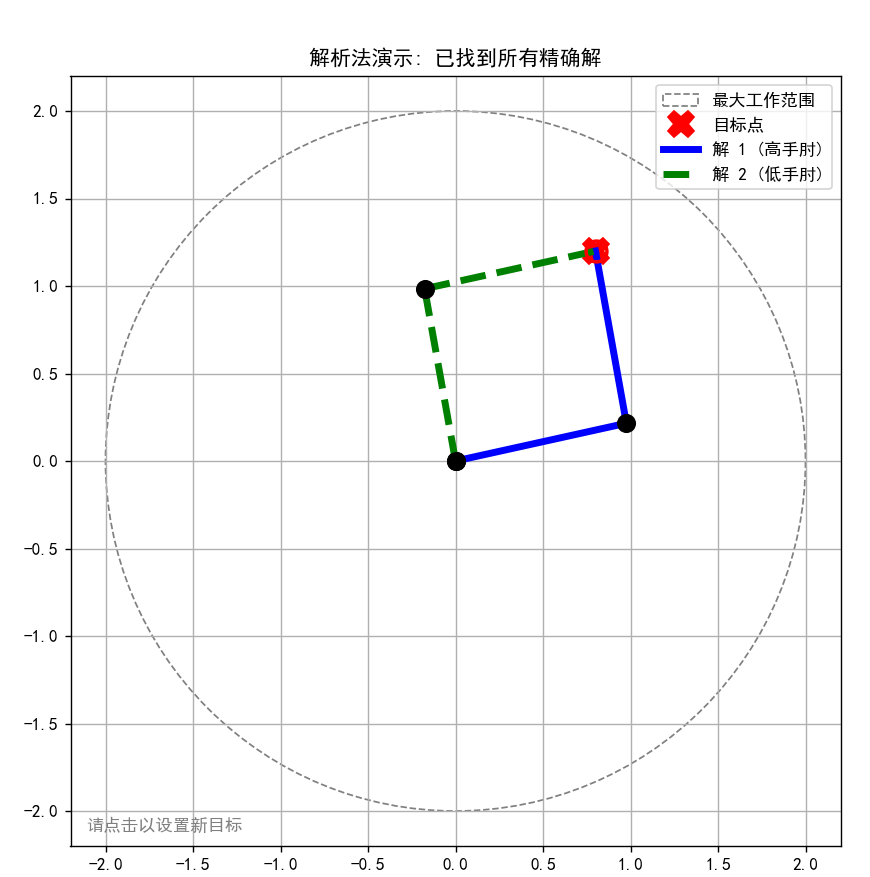

图中的红色叉号表示目标点。蓝色实线与绿色虚线表示两种不同的关节构型，它们从同一个基座出发，通过不同的肘关节位置到达相同的目标。

灰色虚线圆表示图中的最大工作范围。它描述最远边界，不能仅凭这个圆判断是否还存在内部空洞；内部是否可达还要结合两段长度。

图中清楚展示了本节的多解性：**末端位置相同，中间关节位置可以不同。**这与前面两圆交点的解释一致。

> **资料边界：**截图中有点击设置目标的文字，但嵌入 Notebook 后是静态原图。PPT 没有提供该演示的源码、地址或运行命令，也没有展示数值逼近过程。本篇保留教学图与结论，不从标题补写一套演示程序。


## 15. 工程场景中的选择

### 15.1 工业机器人：关注速度与确定性

课件第 22 页以汽车、电子制造等场景说明，高速、高精度和高重复性会影响求解方法的选择。

如果机器人结构支持解析求解，可以将相应公式用于控制器，减少运行时迭代，并通过分支枚举进行构型选择。课件以此说明“用结构设计换取求解性能”的思路。

> **课件表述的边界：**PPT 的“微秒级”“瞬间找到所有解”是对速度优势的强调，不是任意设备与算法的性能保证。实际速度取决于实现和硬件；解析公式也要处理分支与限制。课件提到的“传智教育机器狗”属于其教学例子，本页没有给出该机器人的结构参数或解析算法。

### 15.2 研究与服务机器人：关注结构适应性

课件第 23 页讨论科研、家庭服务和医疗等场景，强调机器人结构多样、任务复杂。数值求解器能够减少针对每种结构重新推导公式的工作，便于处理冗余自由度。

课件指出，后续使用的 IK 库采用数值方法作为求解基础。这一页讲的是方法选择，没有给出库调用代码。

> **补充说明：**数值方法提供处理复杂任务的基础，但避障、能耗优化和关节约束需要在模型或求解问题中明确表达，并不会因为调用了一个逆解接口就自动完成。

两类场景的倾向用于理解选择理由，实际仍要结合机器人结构、任务要求和可用求解器判断。


## 16. 来源与覆盖范围

资料来自[用户提供的课程网盘](https://pan.baidu.com/s/1JTzTYgpIAiSUroQ2-ihJHA?pwd=1234)，提取码为 `1234`。资料目录为“6、嵌入式具身智能机械臂／视频资料／课程ppt”。

本篇主资料为 `具身智能实战04-运动学逆解.pptx`：

| 笔记内容 | 对应 PPT 页码 |
|---|---|
| 课题、正解回顾、实际任务与逆解定义 | 1—4 |
| 非线性、存在性、多样性与奇异性 | 5 |
| 多解的类比、两圆解释与冗余自由度 | 6—8 |
| 工作空间、外部不可达和内部空洞 | 9—10 |
| 奇异性、雅可比秩下降与本节小结 | 11—13 |
| 解析法的思路、二连杆例子和特点 | 14—15 |
| 数值迭代、雅可比、算法及局限 | 16—18 |
| 梯度下降类比及两类方法对比 | 19—20 |
| 二连杆两解演示原图 | 21 |
| 工业、研究与服务机器人的方法选择 | 22—23 |

第 4、20 页的原课对照表已整理进相应章节，第 21 页原图以 Notebook 附件嵌入。移动笔记文件后，图片仍可显示。

本篇未转录配套视频。二连杆距离条件和第 9 节公式是对课件当前几何思路的补充展开；其余边界说明在对应位置注明，未添加 PPT 未展示的项目源码。
